In [1]:
import numpy as np
import pandas as pd
import itertools
from mass_function import MassFunction


原子間の非類似と不明の確信度の図示をします。

In [2]:
ALPHA = 0.1


In [3]:
ROOT = ".."
df_data = pd.read_csv(f"{ROOT}/data/HEA_data.demo.csv", index_col=0)
ELEMENTS = np.array([
    "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu",
    "Zr", "Nb", "Mo", "Tc", "Ru", "Rh", "Pd", "Ag"])


In [4]:
#結果の保存
df_similarity = pd.read_csv("data_executed/elements_similarity.csv", index_col=[0])
df_dissimilarity = pd.read_csv("data_executed/elements_dissimilarity.csv", index_col=[0])
df_unknown = pd.read_csv("data_executed/elements_unknown.csv", index_col=[0])


In [5]:
index = df_similarity.index.tolist()
index[0] = ""
df_similarity.index = index


In [6]:
columns = df_similarity.columns.tolist()
columns[0] = ""
df_similarity.columns = columns

In [7]:
df_similarity

,,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zr,...,Ru|Tc,Rh|Tc,Pd|Tc,Ag|Tc,Rh|Ru,Pd|Ru,Ag|Ru,Pd|Rh,Ag|Rh,Ag|Pd
,1.000000,0.772241,0.757401,0.975527,0.983751,0.900591,0.601309,0.792210,0.794337,0.667691,...,0.0,0.0,0.0,0.0,0.359689,0.558117,0.430612,0.128948,0.703847,0.665628
Ti,0.772241,1.000000,0.437704,0.631663,0.568643,0.873808,0.490967,0.514075,0.573530,0.255004,...,0.0,0.0,0.0,0.0,0.000000,0.082569,0.190000,0.196077,0.090909,0.090909
V,0.757401,0.437704,1.000000,0.925205,0.804575,0.658000,0.345366,0.573530,0.208670,0.592038,...,0.0,0.0,0.0,0.0,0.159664,0.417128,0.359689,0.319060,0.255897,0.249082
Cr,0.975527,0.631663,0.925205,1.000000,0.823042,0.878827,0.453158,0.433400,0.790240,0.458625,...,0.0,0.0,0.0,0.0,0.000000,0.417128,0.335799,0.249082,0.236356,0.297052
Mn,0.983751,0.568643,0.804575,0.823042,1.000000,0.802271,0.217869,0.308710,0.516393,0.531997,...,0.0,0.0,0.0,0.0,0.000000,0.168793,0.442434,0.154522,0.442434,0.387560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pd|Ru,0.558117,0.082569,0.417128,0.417128,0.168793,0.627029,0.561548,0.752114,0.482848,0.100000,...,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,0.050462,0.000000
Ag|Ru,0.430612,0.190000,0.359689,0.335799,0.442434,0.055757,0.236356,0.114745,0.290534,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
Pd|Rh,0.128948,0.196077,0.319060,0.249082,0.154522,0.391756,0.312720,0.614504,0.319060,0.074931,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
Ag|Rh,0.703847,0.090909,0.255897,0.236356,0.442434,0.179999,0.236356,0.249082,0.366474,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.050462,0.000000,0.000000,1.000000,0.000000


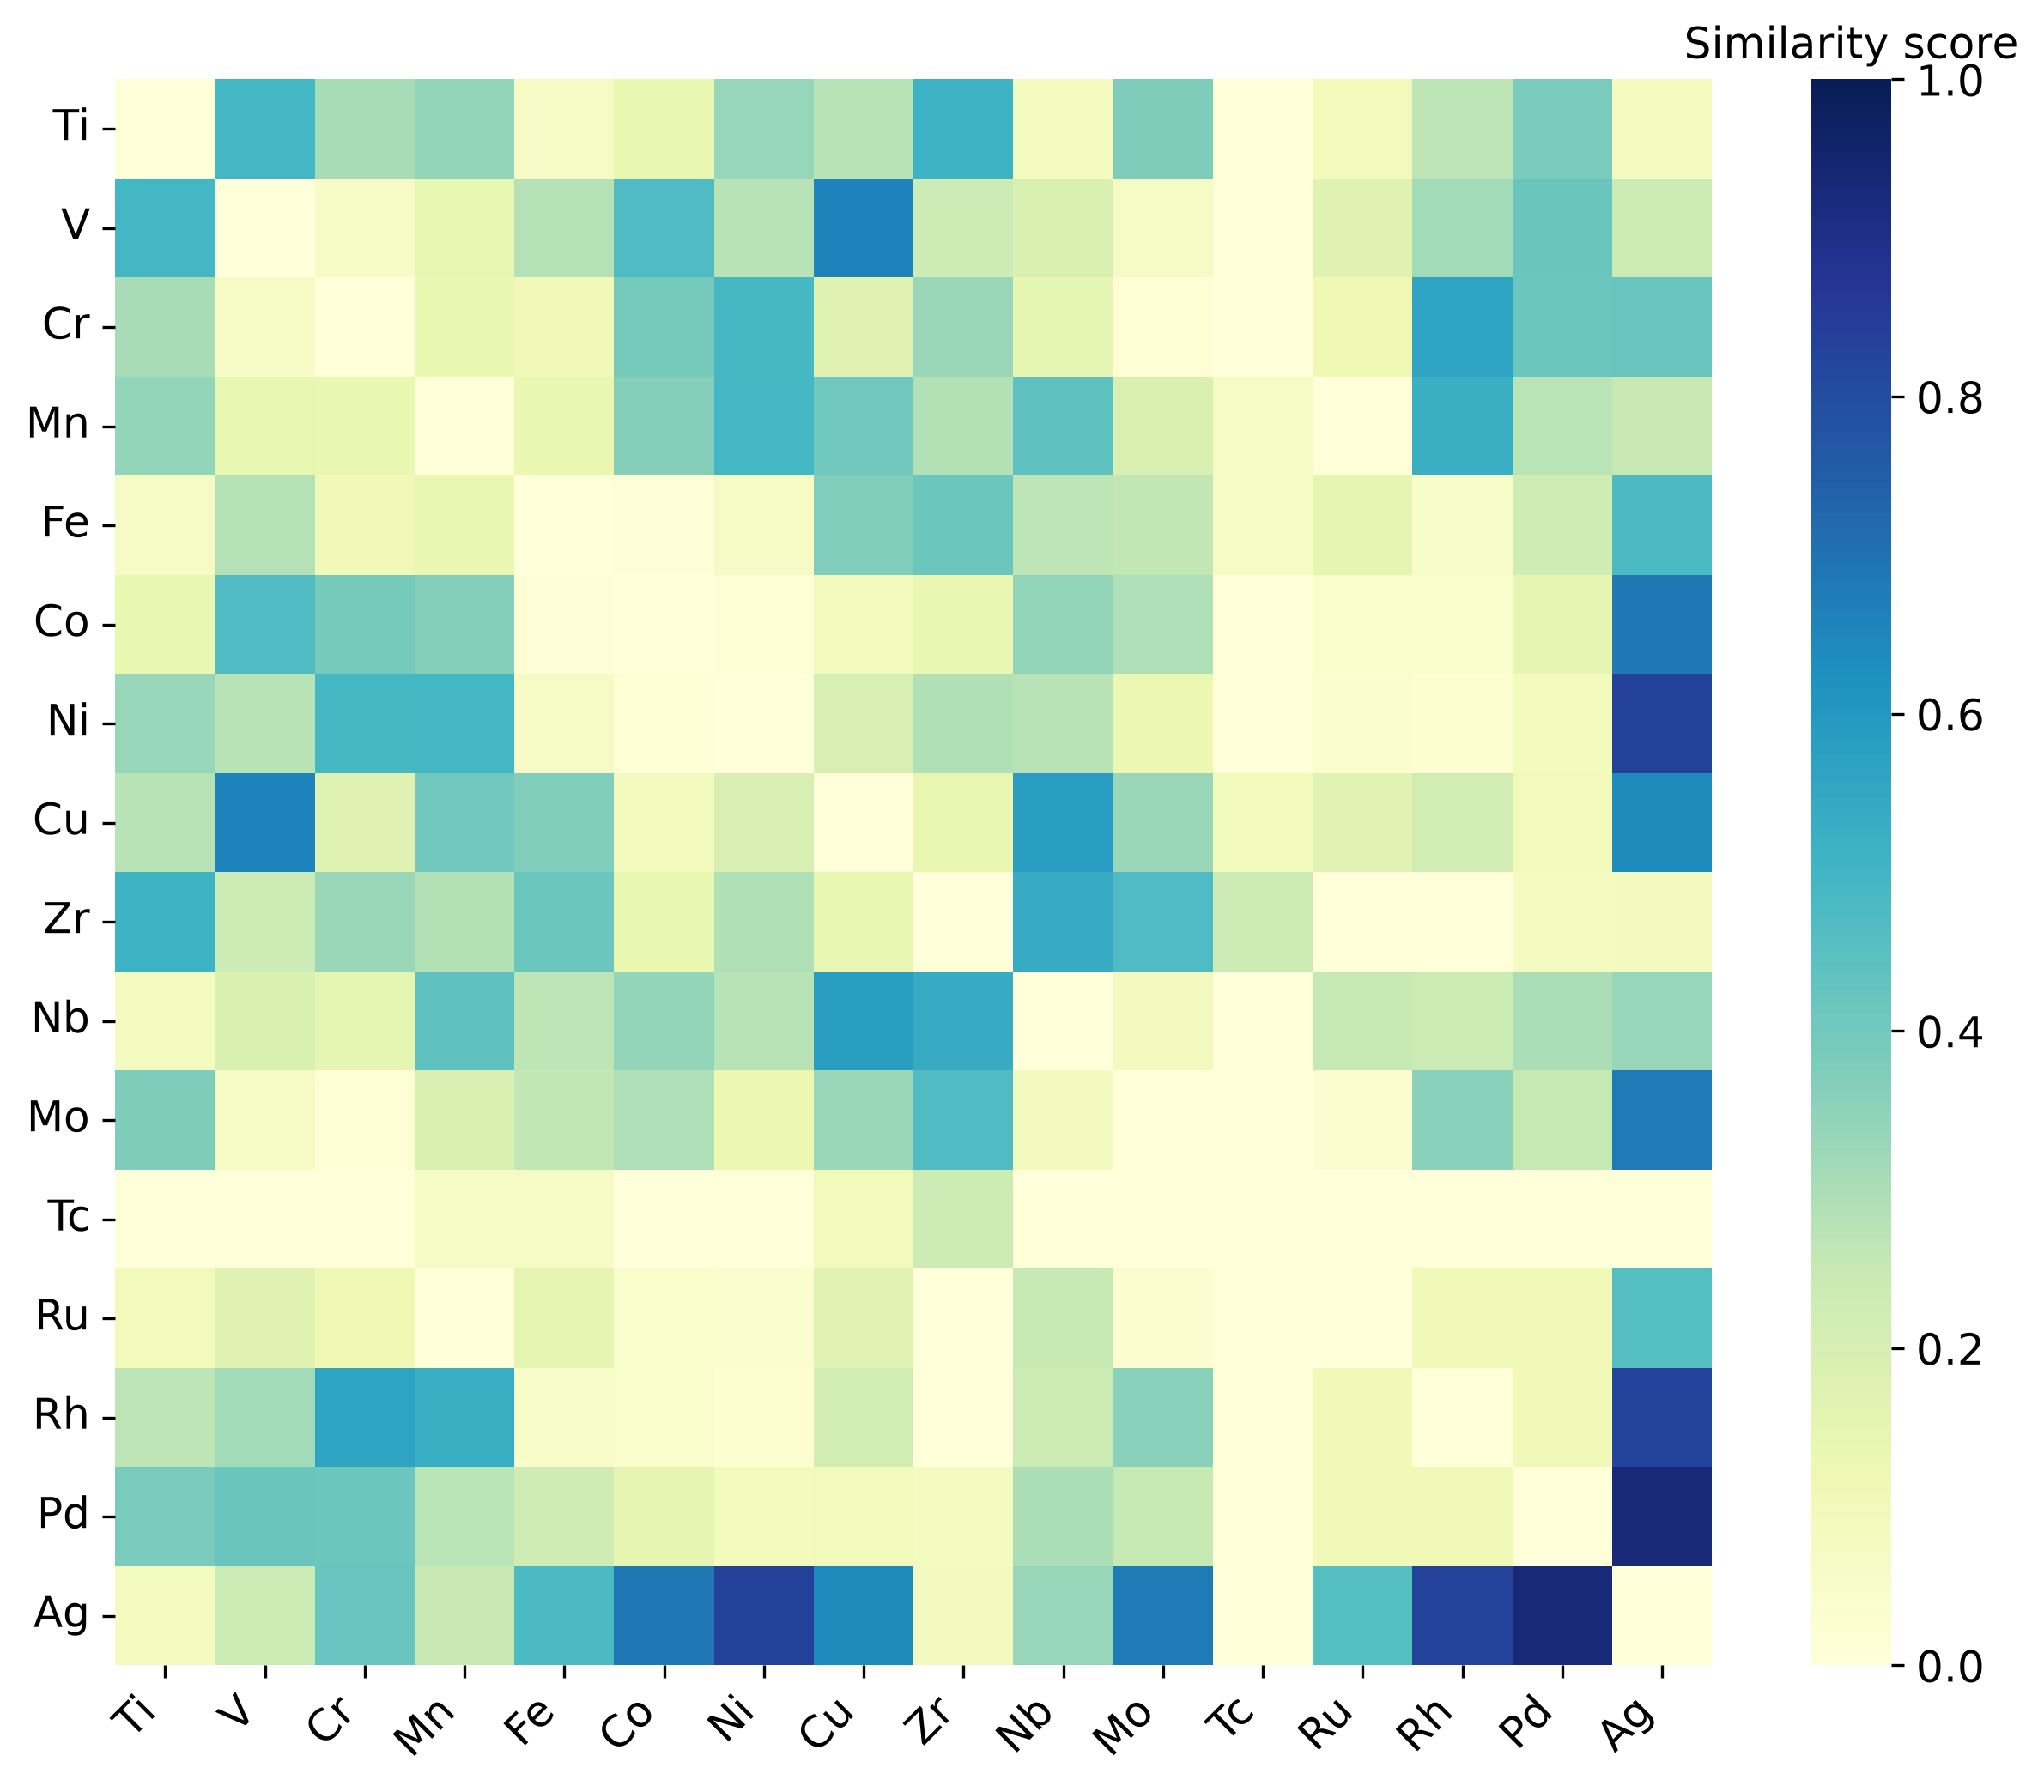

In [8]:
from ERS_misc import plot_similarity_matrix
import matplotlib.pyplot as plt
plot_similarity_matrix(df_dissimilarity, ELEMENTS)


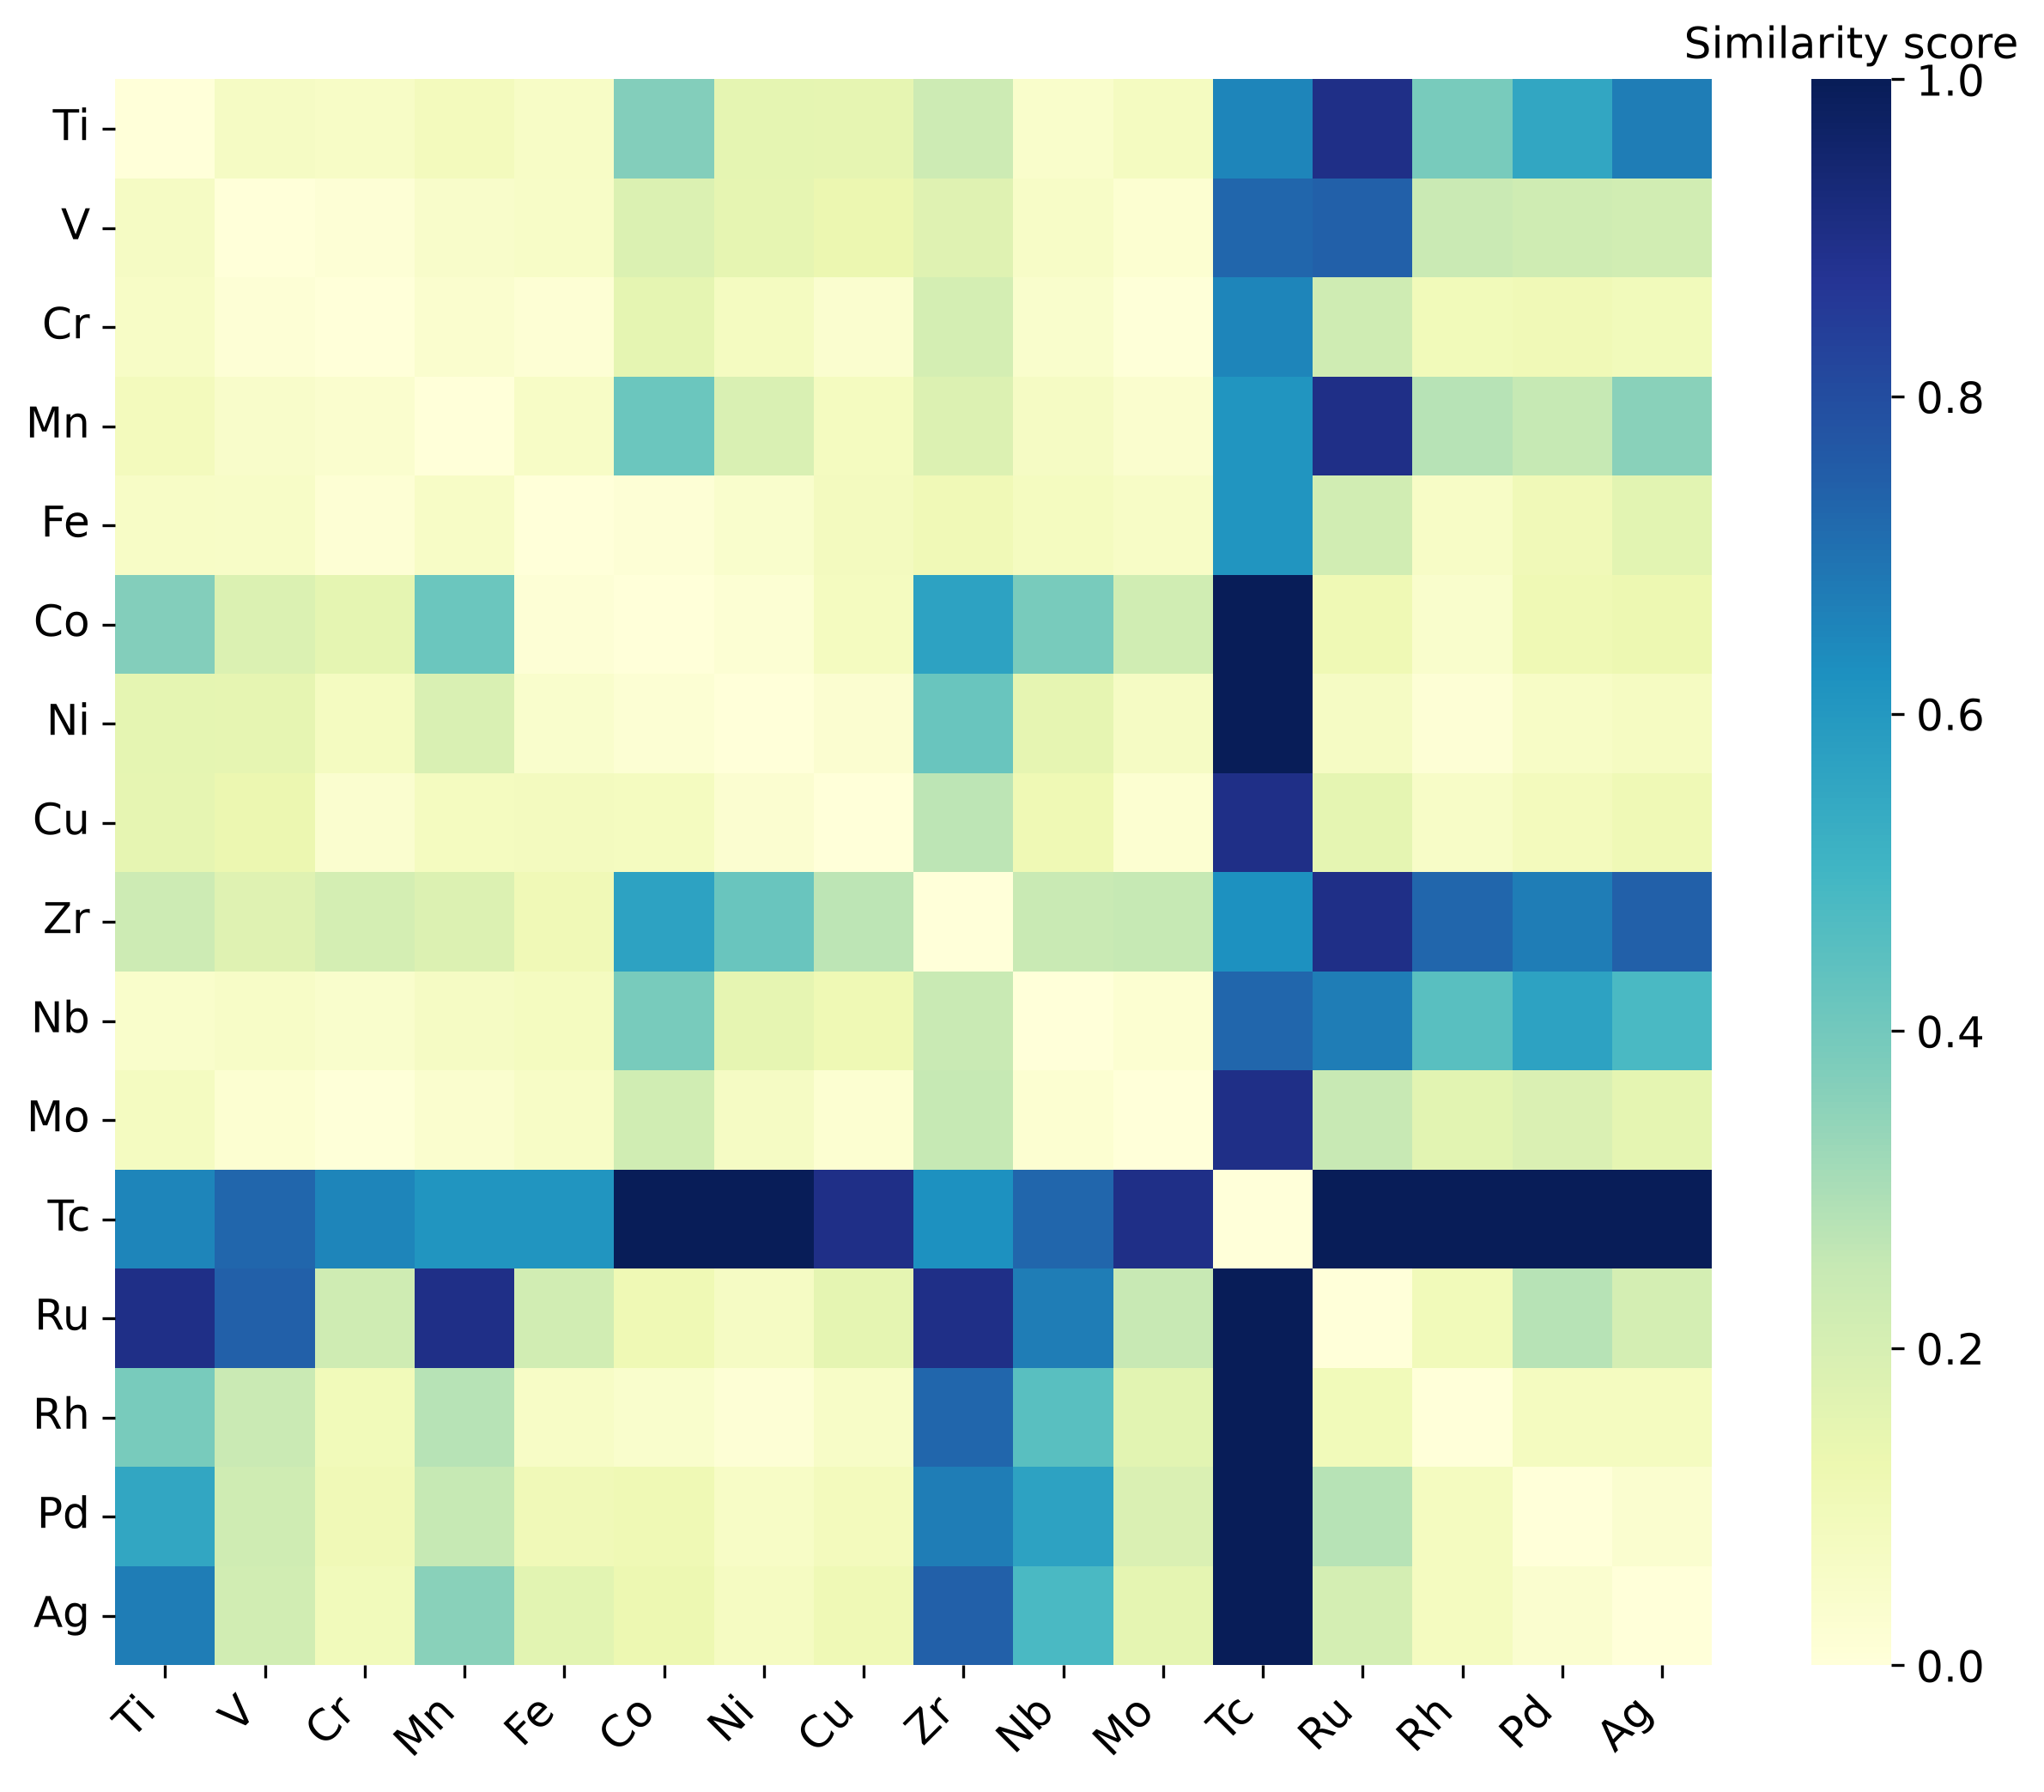

In [9]:
plot_similarity_matrix(df_unknown, ELEMENTS)


不明が多い元素に関してデータ解析をしています。

元素Tcは不明の確信度が多くなっています。
その他にも(Ti,Zr,Nb)-4d元素の組み合わせが不明の確信度が多くなっています。

以下では、一元素毎に存在数を確認します。

In [10]:
occurrence = {}
for element in ELEMENTS:
    _df = df_data[df_data[element]==1]
    occurrence[element] = [_df.shape[0]]
df_occurrence = pd.DataFrame(occurrence, index=["occurrence"]).T.reset_index()
df_occurrence.rename(columns={"index":"element"}, inplace=True)
df_occurrence["occurrence"].mean()
df_occurrence

,element,occurrence
0,Ti,73
1,V,98
2,Cr,132
3,Mn,79
4,Fe,108
5,Co,64
6,Ni,95
7,Cu,102
8,Zr,35
9,Nb,80


上のデータの可視化をします。

<Axes: xlabel='element'>

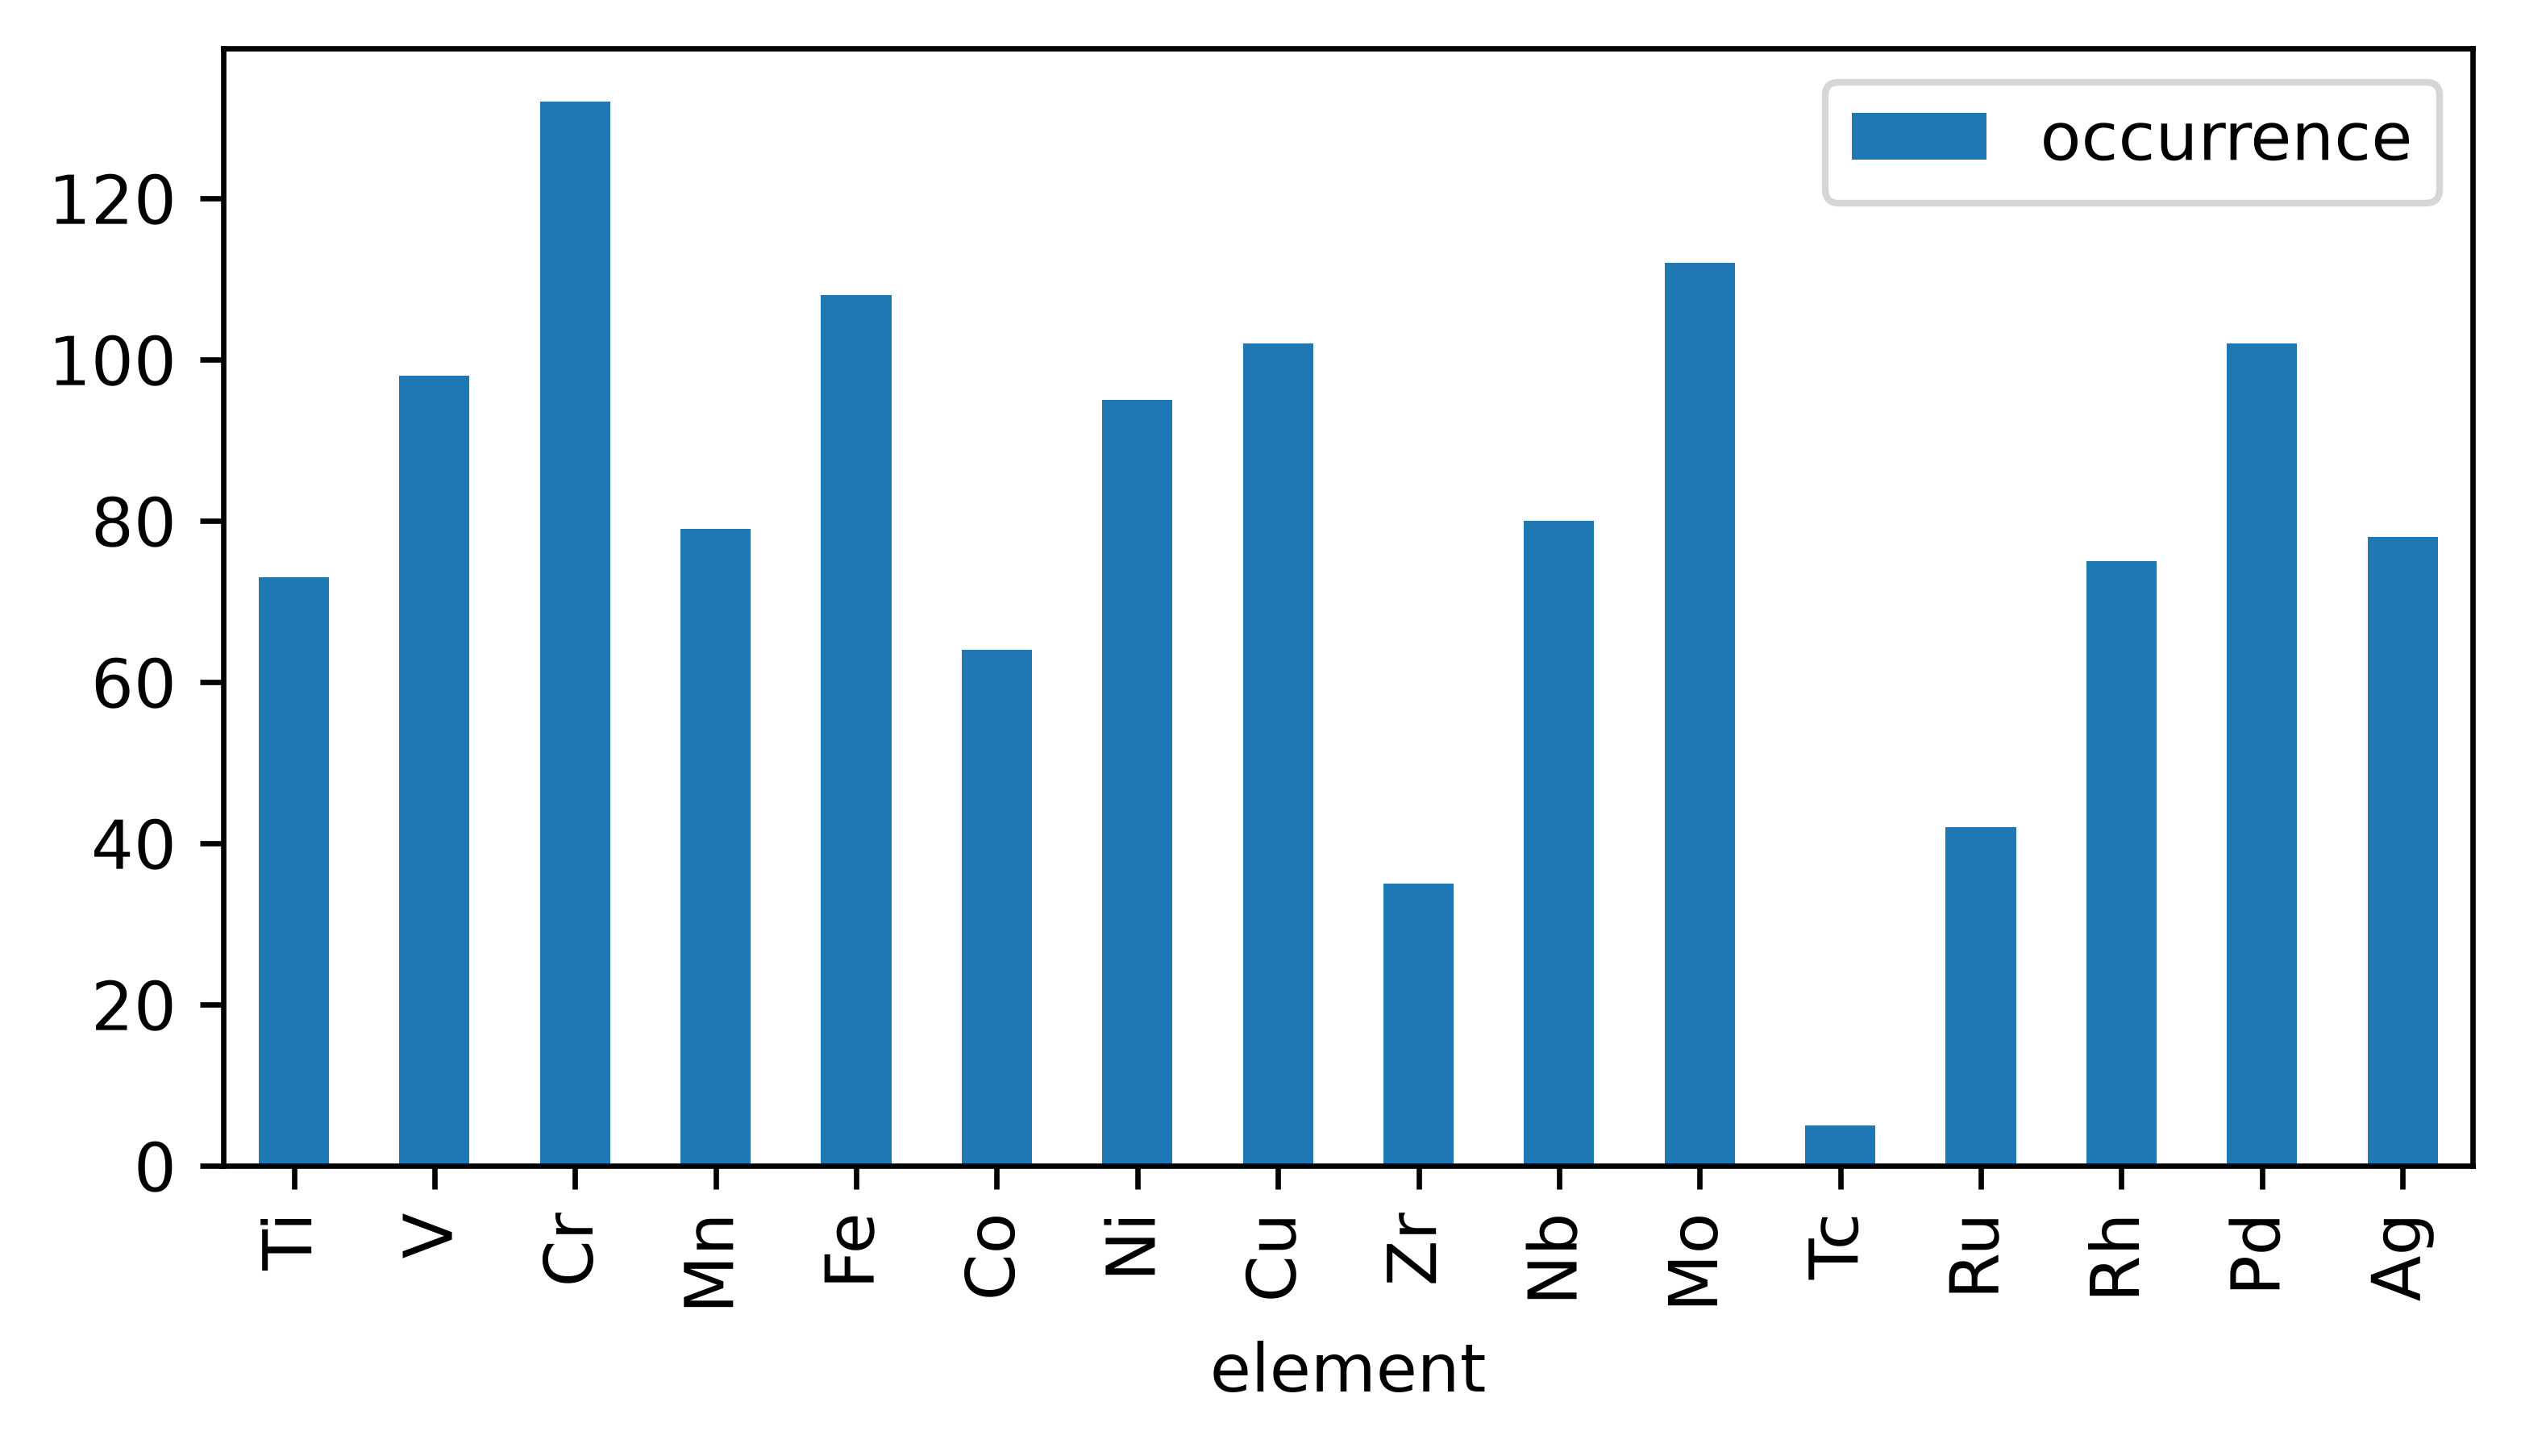

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,3), dpi=600)
df_occurrence.plot.bar(x="element",y="occurrence", ax=ax)


Tcを含む物質は確かにデータインスタンス数が特に少ないことが分かります。
他には不明の確信度が組み合わせとして大きい物質にはTi,Zr,Nb,Ruがあります。
Zr,Ru元素はデータインスタンス数が確かに少なめですが、Ti,Nb元素はデータインスタンス数はあることからTi,Nb元素は観測組み合わせが偏っていると想像できます。

物質探索として、何かしらの物質科学的知見があるせいで、Zr,Tcのデータインスタンス数が小さいのかが気になります。